## Problem Statement

Large Language Models (LLMs) can process increasingly long contexts, but their ability to accurately retrieve information may depend on where that information appears within the input. Even when the relevant information is present, models may struggle to identify it, particularly when it is buried in the middle of a long context.

This project investigates **how the position of relevant information affects an LLM's retrieval accuracy**. Inspired by the research paper *Lost in the Middle: How Language Models Use Long Contexts*, we conduct a controlled experiment using randomly generated key-value pairs.

By placing the target information at different positions—beginning, near-middle, middle, and end—we evaluate whether retrieval accuracy changes while keeping the question, model, and dataset consistent.

The experiment also measures response latency and token usage to explore potential differences in performance across context positions.

In [74]:
#Installs the Python libraries needed to interact with Claude, organize experiment results, and create visualizations.
%pip install anthropic

In [75]:
#Imports the required libraries, securely loads the Anthropic API key, and initializes the Claude model used throughout the experiment.
import random
import time
import pandas as pd
import matplotlib.pyplot as plt

import anthropic
from getpass import getpass

# Enter your Anthropic API key securely
api_key = getpass("Enter your Anthropic API key: ")

# Initialize Anthropic client
client = anthropic.Anthropic(api_key=api_key)

# Select Claude model
MODEL = "claude-haiku-4-5-20251001"

print("Claude client initialized!")
print("Model:", MODEL)

Enter your Anthropic API key: ··········
Claude client initialized!
Model: claude-haiku-4-5-20251001


In [83]:
#Creates 100 random key-value pairs and selects one target pair whose value the model must retrieve.
#A fixed random seed ensures the dataset can be reproduced.
random.seed(42)

pairs = [
    (f"USER{i:03d}", str(random.randint(10000, 99999)))
    for i in range(100)
]

target = pairs[42]

print("Total pairs:", len(pairs))
print("Target:", target)

Total pairs: 100
Target: ('USER042', '57052')


In [84]:
#Creates four versions of the dataset by placing the target key-value pair at the beginning, near the middle, in the middle, and at the end.
#The remaining pairs stay in the same relative order to keep the experiment controlled.
def move_target(pairs, target, position):

    remaining = [
        pair for pair in pairs
        if pair != target
    ]

    result = remaining.copy()
    result.insert(position, target)

    return result


positions = {
    "start": 0,
    "near_middle": 25,
    "middle": 50,
    "end": 99
}

test_cases = {}

for name, position in positions.items():

    test_cases[name] = move_target(
        pairs,
        target,
        position
    )

    actual_position = test_cases[name].index(target) + 1

    print(f"{name}: position {actual_position}")

start: position 1
near_middle: position 26
middle: position 51
end: position 100


In [85]:
#Converts each version of the dataset into a text-based context that can be included in the LLM prompt.
#Each context contains the same key-value pairs but places the target at a different position.
def create_context(pairs):

    return "\n".join(
        f"{key}: {value}"
        for key, value in pairs
    )


contexts = {
    name: create_context(test_pairs)
    for name, test_pairs in test_cases.items()
}

print("Created", len(contexts), "contexts")

Created 4 contexts


In [86]:
#Sends each context and the corresponding question to Claude through the Anthropic API.
#Extracts the model's answer and records whether it matches the expected value, along with response time and token usage.
def evaluate_context(context, target_key, expected_value):

    prompt = f"""
You are given a list of key-value pairs.

Find the value associated with the requested key.

Return only the value.
Do not provide explanations.

Key-value pairs:
{context}

Question:
What is the value associated with {target_key}?
"""

    print("Sending request to Claude...")

    start_time = time.perf_counter()

    try:
        response = client.messages.create(
            model=MODEL,
            max_tokens=100,
            messages=[
                {
                    "role": "user",
                    "content": prompt
                }
            ]
        )

        print("Claude response received!")

    except Exception as e:
        print("Error type:", type(e).__name__)
        print("Error message:", str(e))
        raise

    latency = time.perf_counter() - start_time

    # Extract Claude's response
    predicted_value = "".join(
        block.text
        for block in response.content
        if block.type == "text"
    ).strip()

    # Compare predicted value with expected value
    correct = predicted_value == expected_value

    return {
        "predicted_value": predicted_value,
        "expected_value": expected_value,
        "correct": correct,
        "latency_seconds": round(latency, 3),
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens
    }

In [87]:
#Runs the evaluation across all four target positions and organizes the results into a Pandas DataFrame for comparison.
target_key, expected_value = target

results = []

for position_name, context in contexts.items():

    print(f"\nTesting position: {position_name}")

    result = evaluate_context(
        context=context,
        target_key=target_key,
        expected_value=expected_value
    )

    result["position"] = position_name

    results.append(result)

# Convert results into a pandas DataFrame
df = pd.DataFrame(results)

# Arrange columns
df = df[
    [
        "position",
        "expected_value",
        "predicted_value",
        "correct",
        "latency_seconds",
        "input_tokens",
        "output_tokens"
    ]
]

display(df)


Testing position: start
Sending request to Claude...
Claude response received!

Testing position: near_middle
Sending request to Claude...
Claude response received!

Testing position: middle
Sending request to Claude...
Claude response received!

Testing position: end
Sending request to Claude...
Claude response received!


,position,expected_value,predicted_value,correct,latency_seconds,input_tokens,output_tokens
0,start,57052,57052,True,0.433,762,6
1,near_middle,57052,57052,True,0.408,762,6
2,middle,57052,57052,True,0.490,762,6
3,end,57052,57052,True,0.430,762,6


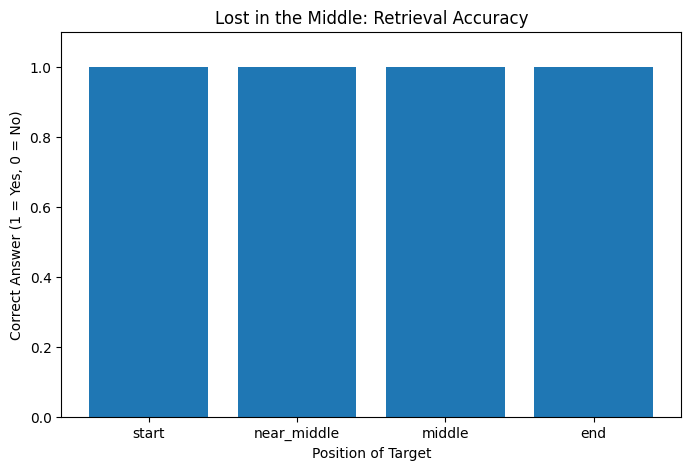

In [88]:
#Creates a bar chart showing whether Claude retrieved the correct value at each position.
#This helps us identify potential differences in retrieval performance based on where the target appears.
plt.figure(figsize=(8, 5))

plt.bar(
    df["position"],
    df["correct"].astype(int)
)

plt.title("Lost in the Middle: Retrieval Accuracy")
plt.xlabel("Position of Target")
plt.ylabel("Correct Answer (1 = Yes, 0 = No)")
plt.ylim(0, 1.1)

plt.show()

In [89]:
#Exports the evaluation results to a CSV file so they can be reused for further analysis, visualization, or documentation.
df.to_csv(
    "lost_in_the_middle_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
